Loan Default Prediction System — Enhanced Notebook
This notebook preserves the original project's four classifiers (Logistic Regression, Random Forest, SVM with RBF kernel, and XGBoost) and adds safer data loading, validation, validation-based threshold selection, PR-AUC, diagnostic plots, an interactive predictor, explainability, and downloadable artifacts.

Target: Defaulted (1 = default, 0 = no default). Because defaults are rare, do not judge models by accuracy alone. This is an educational project, not a lending decision system.


0. Install dependencies (Google Colab)
Cell 2 of 35

0. Install dependencies (Google Colab)
Run this cell once if the imports in the next section report a missing package. In a fresh Colab runtime, it is safe to run before continuing.

In [17]:
%pip -q install xgboost ipywidgets joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 48.3 MB/s eta 0:00:00


In [18]:
import io
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix, classification_report
)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
print("Imports successful.")

Imports successful.


In [19]:
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file was uploaded. Run this cell again and select your CSV file.")
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_names:
        raise ValueError("The uploaded files do not include a .csv file. Please upload Module 3 Project Data.csv.")
    csv_name = csv_names[0]
    df_raw = pd.read_csv(io.BytesIO(uploaded[csv_name]))
    print(f"Loaded: {csv_name}")
except ImportError:
    candidate = "Module 3 Project Data.csv"
    if not os.path.exists(candidate):
        raise FileNotFoundError(
            "Google Colab upload is unavailable in this environment and the CSV was not found locally. "
            "Upload the CSV in Colab or place it beside this notebook."
        )
    df_raw = pd.read_csv(candidate)
    print(f"Loaded local file: {candidate}")

print("Dataset shape:", df_raw.shape)
display(df_raw.head())

Saving Module 3 Project Data.csv to Module 3 Project Data (1).csv
Loaded: Module 3 Project Data (1).csv
Dataset shape: (10000, 5)


,Index,Employed,Bank Balance,Annual Salary,Defaulted?
0,1,1,8754.36,532339.56,0
1,2,0,9806.16,145273.56,0
2,3,1,12882.60,381205.68,0
3,4,1,6351.00,428453.88,0
4,5,1,9427.92,461562.00,0


In [20]:
expected = {"Index", "Employed", "Bank Balance", "Annual Salary", "Defaulted?"}
missing_columns = expected - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}. Found: {df_raw.columns.tolist()}")

print("Data types before cleaning:")
display(df_raw.dtypes.rename("dtype").to_frame())
print("Missing values by column:")
display(df_raw.isna().sum().rename("missing_count").to_frame())
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))

# Work on a copy; don't silently remove records.
df = df_raw.copy()
# Drop Index only if it is a unique sequential row identifier.
idx = pd.to_numeric(df["Index"], errors="coerce")
is_sequential_id = idx.notna().all() and idx.is_unique and (
    np.array_equal(idx.to_numpy(), np.arange(1, len(df) + 1)) or
    np.array_equal(idx.to_numpy(), np.arange(0, len(df)))
)
if is_sequential_id:
    df = df.drop(columns=["Index"])
    print("Dropped Index because it is a unique sequential row identifier.")
else:
    print("Kept Index: it did not meet the sequential-identifier check. Review whether it is a meaningful feature.")

df = df.rename(columns={
    "Bank Balance": "Bank_Balance",
    "Annual Salary": "Annual_Salary",
    "Defaulted?": "Defaulted"
})
required_model_cols = ["Employed", "Bank_Balance", "Annual_Salary", "Defaulted"]
for col in required_model_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Invalid numeric values become NaN and are reported; drop only rows unusable for these model fields.
print("Missing/invalid values in model columns after numeric conversion:")
display(df[required_model_cols].isna().sum().rename("count").to_frame())
if df[required_model_cols].isna().any().any():
    before = len(df)
    df = df.dropna(subset=required_model_cols).copy()
    print(f"Dropped {before-len(df)} row(s) with missing or non-numeric required values.")

if not set(df["Defaulted"].unique()).issubset({0, 1}):
    raise ValueError(f"Target Defaulted must contain only 0 and 1. Found: {sorted(df['Defaulted'].unique().tolist())}")
if not set(df["Employed"].unique()).issubset({0, 1}):
    raise ValueError(f"Employed must be coded 0/1. Found: {sorted(df['Employed'].unique().tolist())}")
if (df[["Bank_Balance", "Annual_Salary"]] < 0).any().any():
    warnings.warn("Negative bank balance or salary values were found. Verify these values are valid for your dataset.")

# Report duplicates; don't automatically remove them because identical customer records may be legitimate.
print("Rows available for modeling:", len(df))
print("Duplicate rows after normalization (reported, not automatically removed):", int(df.duplicated().sum()))
print("Target counts:")
display(df["Defaulted"].value_counts().sort_index().rename(index={0:"No default (0)",1:"Default (1)"}).to_frame("count"))
if df["Defaulted"].nunique() != 2:
    raise ValueError("Both target classes (0 and 1) must be present to train and evaluate classifiers.")

Data types before cleaning:


,dtype
Index,int64
Employed,int64
Bank Balance,float64
Annual Salary,float64
Defaulted?,int64


Missing values by column:


,missing_count
Index,0
Employed,0
Bank Balance,0
Annual Salary,0
Defaulted?,0


Exact duplicate rows: 0
Dropped Index because it is a unique sequential row identifier.
Missing/invalid values in model columns after numeric conversion:


,count
Employed,0
Bank_Balance,0
Annual_Salary,0
Defaulted,0


Rows available for modeling: 10000
Duplicate rows after normalization (reported, not automatically removed): 0
Target counts:


,count
Defaulted,
No default (0),9667
Default (1),333


,count,mean,std,min,25%,50%,75%,max
Employed,10000.0,0.705600,0.455795,0.00,0.00,1.00,1.00,1.00
Bank_Balance,10000.0,10024.498524,5804.579486,0.00,5780.79,9883.62,13995.66,31851.84
Annual_Salary,10000.0,402203.782224,160039.674988,9263.64,256085.52,414631.74,525692.76,882650.76
Defaulted,10000.0,0.033300,0.179428,0.00,0.00,0.00,0.00,1.00


Target proportions:


,proportion
Defaulted,
0,0.9667
1,0.0333


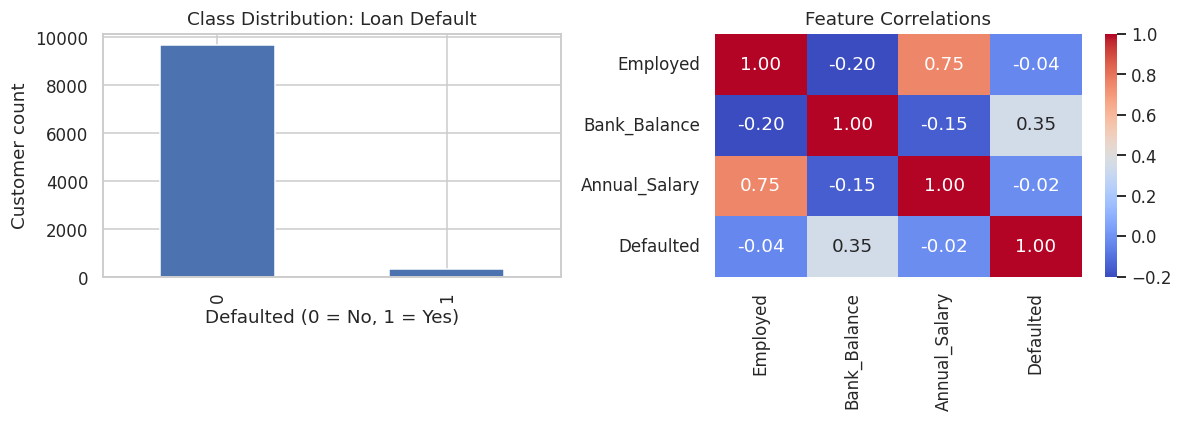

In [21]:
display(df.describe().T)
print("Target proportions:")
display(df["Defaulted"].value_counts(normalize=True).rename("proportion").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["Defaulted"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Class Distribution: Loan Default")
axes[0].set_xlabel("Defaulted (0 = No, 1 = Yes)")
axes[0].set_ylabel("Customer count")
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Feature Correlations")
plt.tight_layout()
plt.show()

In [22]:
FEATURES = ["Employed", "Bank_Balance", "Annual_Salary"]
TARGET = "Defaulted"
X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE, stratify=y_trainval
)
print(f"Train: {len(X_train):,} rows | Validation: {len(X_val):,} rows | Test: {len(X_test):,} rows")
print("Default rate by split:")
display(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True)
}).rename(index={0:"No default",1:"Default"}))

# XGBoost's class imbalance weight is estimated from training labels only.
scale_pos_weight = max(1.0, (y_train == 0).sum() / max(1, (y_train == 1).sum()))
print(f"XGBoost scale_pos_weight (training only): {scale_pos_weight:.2f}")

Train: 6,000 rows | Validation: 2,000 rows | Test: 2,000 rows
Default rate by split:


,train,validation,test
Defaulted,,,
No default,0.966667,0.967,0.9665
Default,0.033333,0.033,0.0335


XGBoost scale_pos_weight (training only): 29.00


In [23]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=scale_pos_weight, eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest
Trained: SVM (RBF)
Trained: XGBoost


In [24]:
thresholds = {}
validation_summary = {}
for name, model in models.items():
    val_prob = model.predict_proba(X_val)[:, 1]
    precision, recall, pr_thresholds = precision_recall_curve(y_val, val_prob)
    # precision_recall_curve returns one more precision/recall value than thresholds.
    if len(pr_thresholds) == 0:
        threshold = 0.5
        best_f1 = 0.0
    else:
        f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
        best_idx = int(np.nanargmax(f1_values))
        threshold = float(pr_thresholds[best_idx])
        best_f1 = float(f1_values[best_idx])
    thresholds[name] = threshold
    validation_summary[name] = {"validation_f1_at_selected_threshold": best_f1, "selected_threshold": threshold}

display(pd.DataFrame(validation_summary).T.sort_values("validation_f1_at_selected_threshold", ascending=False))

,validation_f1_at_selected_threshold,selected_threshold
Logistic Regression,0.551724,0.953480
XGBoost,0.453901,0.865068
Random Forest,0.441860,0.180000
SVM (RBF),0.419512,0.185077


In [25]:
results = {}
test_probabilities = {}
test_predictions = {}
roc_data = {}
pr_data = {}

for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= thresholds[name]).astype(int)
    test_probabilities[name] = prob
    test_predictions[name] = pred
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "PR_AUC": average_precision_score(y_test, prob),
        "Threshold": thresholds[name],
        "Confusion_Matrix": confusion_matrix(y_test, pred, labels=[0, 1]),
    }
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    roc_data[name] = (fpr, tpr)
    pr_data[name] = (rec, prec)

results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("PR_AUC", ascending=False)
display(results_df.drop(columns="Confusion_Matrix").style.format("{:.4f}"))
print("Primary comparison metric: PR-AUC (average precision), useful for rare positive classes.")

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
Logistic Regression,0.9675,0.5200,0.3881,0.4444,0.9479,0.5129,0.9535
Random Forest,0.9475,0.3390,0.5970,0.4324,0.8947,0.4281,0.1800
XGBoost,0.9590,0.4118,0.5224,0.4605,0.9324,0.4135,0.8651
SVM (RBF),0.9280,0.2873,0.7761,0.4194,0.9200,0.3134,0.1851


Primary comparison metric: PR-AUC (average precision), useful for rare positive classes.


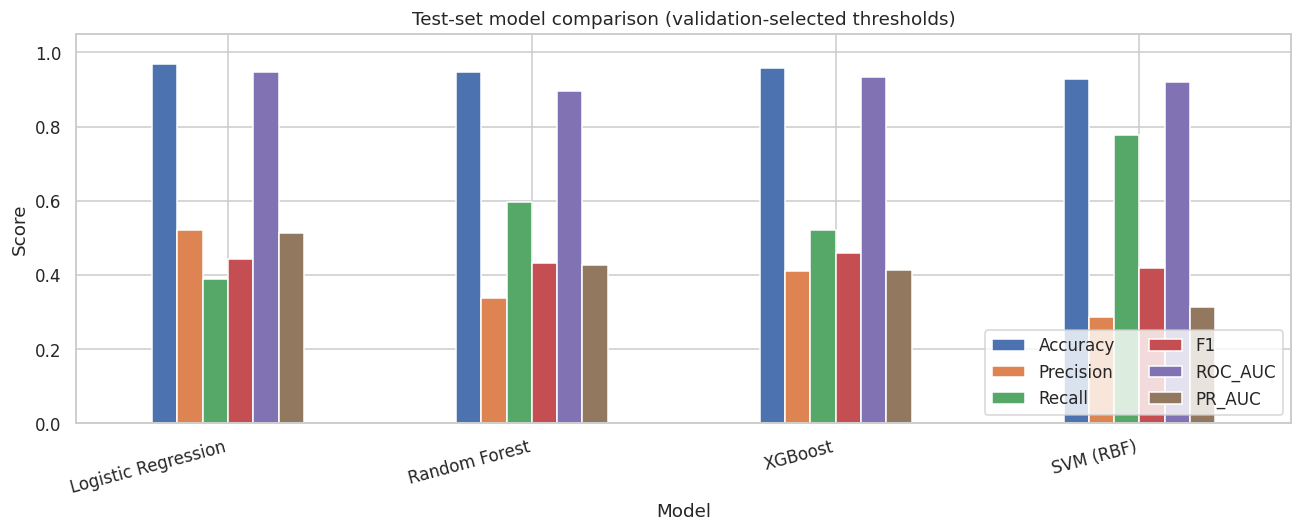

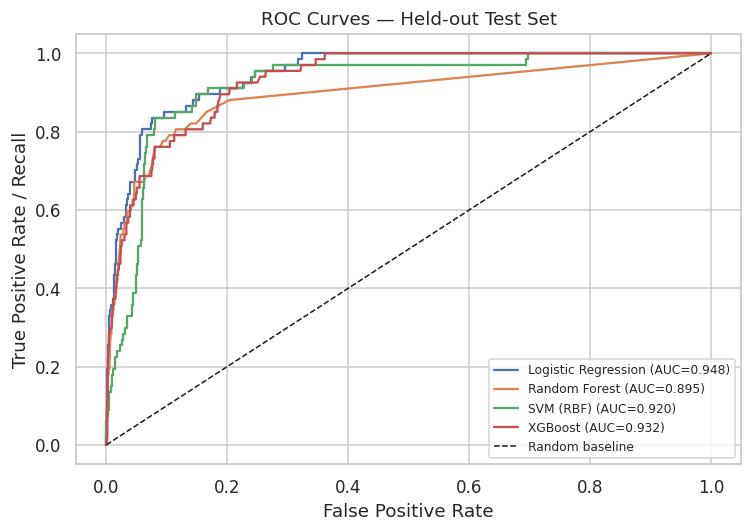

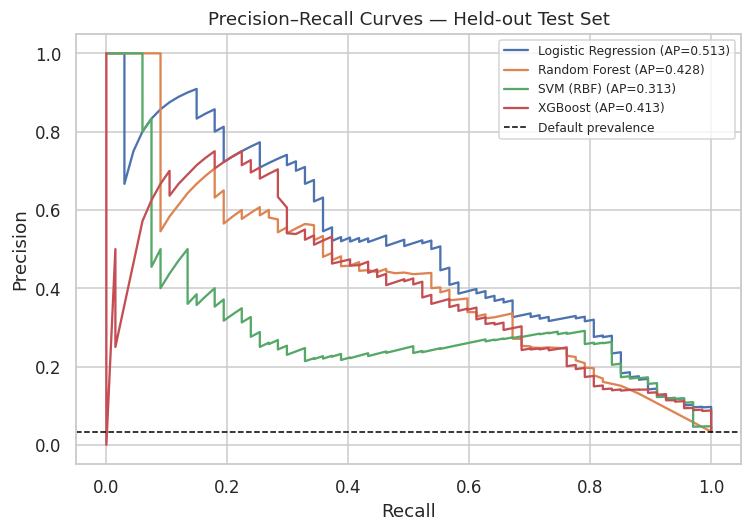

In [26]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
ax = results_df[metric_cols].plot(kind="bar", figsize=(12, 5))
ax.set_title("Test-set model comparison (validation-selected thresholds)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
for name, (fpr, tpr) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['ROC_AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curves — Held-out Test Set")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
for name, (rec, prec) in pr_data.items():
    plt.plot(rec, prec, label=f"{name} (AP={results[name]['PR_AUC']:.3f})")
plt.axhline(y=float(y_test.mean()), linestyle="--", color="black", linewidth=1, label="Default prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — Held-out Test Set")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

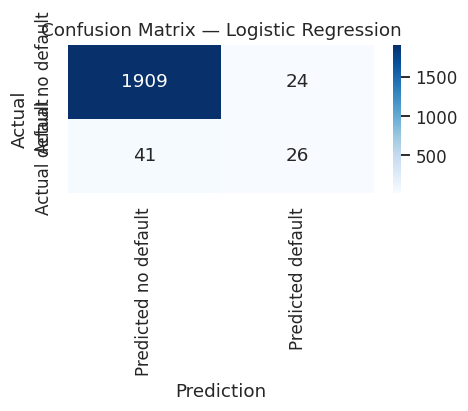

Classification report — Logistic Regression (threshold=0.9535)
              precision    recall  f1-score   support

  No default       0.98      0.99      0.98      1933
     Default       0.52      0.39      0.44        67

    accuracy                           0.97      2000
   macro avg       0.75      0.69      0.71      2000
weighted avg       0.96      0.97      0.97      2000



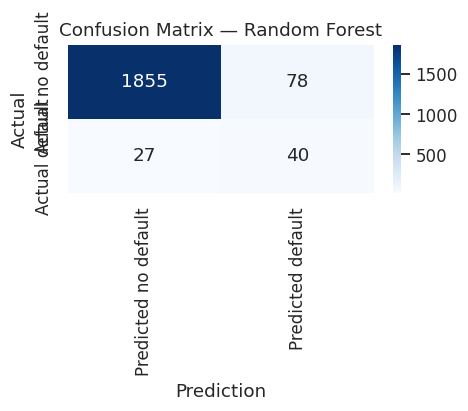

Classification report — Random Forest (threshold=0.1800)
              precision    recall  f1-score   support

  No default       0.99      0.96      0.97      1933
     Default       0.34      0.60      0.43        67

    accuracy                           0.95      2000
   macro avg       0.66      0.78      0.70      2000
weighted avg       0.96      0.95      0.95      2000



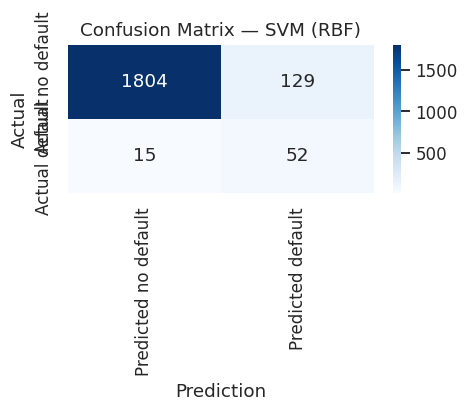

Classification report — SVM (RBF) (threshold=0.1851)
              precision    recall  f1-score   support

  No default       0.99      0.93      0.96      1933
     Default       0.29      0.78      0.42        67

    accuracy                           0.93      2000
   macro avg       0.64      0.85      0.69      2000
weighted avg       0.97      0.93      0.94      2000



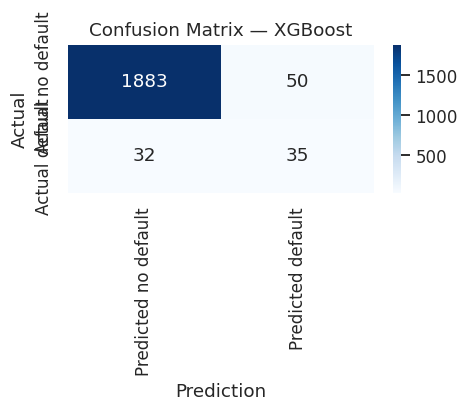

Classification report — XGBoost (threshold=0.8651)
              precision    recall  f1-score   support

  No default       0.98      0.97      0.98      1933
     Default       0.41      0.52      0.46        67

    accuracy                           0.96      2000
   macro avg       0.70      0.75      0.72      2000
weighted avg       0.96      0.96      0.96      2000



In [27]:
for name in models:
    cm = results[name]["Confusion_Matrix"]
    plt.figure(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Predicted no default", "Predicted default"],
                yticklabels=["Actual no default", "Actual default"])
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediction")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
    print(f"Classification report — {name} (threshold={thresholds[name]:.4f})")
    print(classification_report(y_test, test_predictions[name], labels=[0, 1],
                                target_names=["No default", "Default"], zero_division=0))

Top model by test PR-AUC: Logistic Regression
Test PR-AUC: 0.5129
Validation-selected threshold: 0.9535


,Random Forest,XGBoost
Bank_Balance,0.802485,0.773393
Annual_Salary,0.187485,0.112888
Employed,0.010030,0.113719


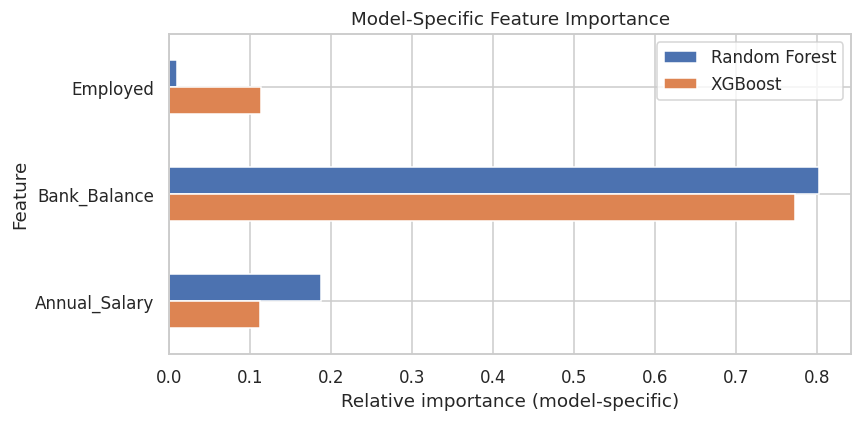

,Logistic coefficient (scaled features)
Annual_Salary,-0.120003
Employed,0.312729
Bank_Balance,2.902305


In [28]:
best_model_name = results_df["PR_AUC"].idxmax()
best_model = models[best_model_name]
best_threshold = thresholds[best_model_name]
print("Top model by test PR-AUC:", best_model_name)
print(f"Test PR-AUC: {results[best_model_name]['PR_AUC']:.4f}")
print(f"Validation-selected threshold: {best_threshold:.4f}")

# Tree-based feature importance; both models are fitted above.
rf = models["Random Forest"]
xgb = models["XGBoost"]
importance_df = pd.DataFrame({
    "Random Forest": rf.feature_importances_,
    "XGBoost": xgb.feature_importances_
}, index=FEATURES)
display(importance_df.sort_values("Random Forest", ascending=False))
importance_df.plot(kind="barh", figsize=(8, 4))
plt.title("Model-Specific Feature Importance")
plt.xlabel("Relative importance (model-specific)")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

if best_model_name == "Logistic Regression":
    coef = best_model.named_steps["model"].coef_[0]
    display(pd.Series(coef, index=FEATURES, name="Logistic coefficient (scaled features)").sort_values())
else:
    print("For the selected model, use the tree importance chart as a global summary; it does not explain causation or every individual prediction.")

In [29]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    employed_widget = widgets.Dropdown(options=[("Employed", 1), ("Not employed", 0)], value=1, description="Employment:")
    balance_widget = widgets.FloatText(value=float(df["Bank_Balance"].median()), description="Bank balance:")
    salary_widget = widgets.FloatText(value=float(df["Annual_Salary"].median()), description="Annual salary:")
    predict_button = widgets.Button(description="Predict default risk", button_style="primary")
    prediction_output = widgets.Output()

    def _predict_customer(_):
        with prediction_output:
            clear_output(wait=True)
            row = pd.DataFrame([{
                "Employed": int(employed_widget.value),
                "Bank_Balance": float(balance_widget.value),
                "Annual_Salary": float(salary_widget.value),
            }], columns=FEATURES)
            if row[["Bank_Balance", "Annual_Salary"]].isna().any().any() or (row[["Bank_Balance", "Annual_Salary"]] < 0).any().any():
                print("Please enter valid non-negative bank balance and salary values.")
                return
            probability = float(best_model.predict_proba(row)[0, 1])
            predicted_class = int(probability >= best_threshold)
            risk = "Higher estimated risk" if predicted_class == 1 else "Lower estimated risk"
            print(f"Model: {best_model_name}")
            print(f"Estimated default probability: {probability:.1%}")
            print(f"Decision threshold: {best_threshold:.3f}")
            print(f"Predicted class: {predicted_class} ({'Default' if predicted_class else 'No default'})")
            print(f"Demo risk label: {risk}")
            print("This is a model estimate, not a guarantee or a lending recommendation.")

    predict_button.on_click(_predict_customer)
    display(widgets.VBox([employed_widget, balance_widget, salary_widget, predict_button, prediction_output]))
except Exception as e:
    print("Interactive widgets could not be displayed in this environment.")
    print("You can still call the prediction code manually in the next cell. Details:", repr(e))

In [30]:
sample_customer = pd.DataFrame([{
    "Employed": 1,
    "Bank_Balance": float(df["Bank_Balance"].median()),
    "Annual_Salary": float(df["Annual_Salary"].median()),
}], columns=FEATURES)
sample_probability = best_model.predict_proba(sample_customer)[0, 1]
print(f"Estimated default probability: {sample_probability:.1%}")
print("Predicted class:", int(sample_probability >= best_threshold))

Estimated default probability: 5.3%
Predicted class: 0


In [31]:
# Export only metric columns; confusion matrices are not suitable as scalar CSV cells.
export_results = results_df.drop(columns="Confusion_Matrix").copy()
comparison_path = "loan_default_model_comparison.csv"
export_results.to_csv(comparison_path, index_label="Model")

bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "features": FEATURES,
    "target": TARGET,
    "selection_metric": "PR_AUC",
    "note": "Educational model bundle. Not validated for real lending decisions."
}
model_path = "loan_default_best_model.joblib"
joblib.dump(bundle, model_path)
print("Saved:", comparison_path)
print("Saved:", model_path)
display(export_results.head())

Saved: loan_default_model_comparison.csv
Saved: loan_default_best_model.joblib


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold
Logistic Regression,0.9675,0.52,0.38806,0.444444,0.947889,0.512918,0.95348
Random Forest,0.9475,0.338983,0.597015,0.432432,0.894665,0.428057,0.18
XGBoost,0.959,0.411765,0.522388,0.460526,0.932396,0.413497,0.865068
SVM (RBF),0.928,0.287293,0.776119,0.419355,0.919984,0.313408,0.185077


In [32]:
# In Google Colab, these calls trigger downloads to your computer.
try:
    from google.colab import files
    files.download("loan_default_best_model.joblib")
    files.download("loan_default_model_comparison.csv")
except ImportError:
    print("Not running in Google Colab. Files are saved in the current working directory:")
    print(os.path.abspath("loan_default_best_model.joblib"))
    print(os.path.abspath("loan_default_model_comparison.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
print(f"Rows used: {len(df):,}")
print(f"Default rate: {y.mean():.2%}")
print(f"Best model by test PR-AUC: {best_model_name}")
print(f"Test PR-AUC: {results[best_model_name]['PR_AUC']:.4f}")
print(f"Test ROC-AUC: {results[best_model_name]['ROC_AUC']:.4f}")
print(f"Test precision / recall / F1: {results[best_model_name]['Precision']:.4f} / {results[best_model_name]['Recall']:.4f} / {results[best_model_name]['F1']:.4f}")
print(f"Validation-selected threshold: {best_threshold:.4f}")
print("Remember: scores are from this run and are not guaranteed to reproduce on different splits or software versions.")

Rows used: 10,000
Default rate: 3.33%
Best model by test PR-AUC: Logistic Regression
Test PR-AUC: 0.5129
Test ROC-AUC: 0.9479
Test precision / recall / F1: 0.5200 / 0.3881 / 0.4444
Validation-selected threshold: 0.9535
Remember: scores are from this run and are not guaranteed to reproduce on different splits or software versions.
